# Quantitative Financial Risk & Market Sensitivity Analysis (CAPM)
**First General Review — Sessions 1 to 6**

This project applies quantitative statistics and financial modeling in Python to evaluate risk, the statistical significance of returns, and market sensitivity ($\beta$) for a tech-heavy equity portfolio benchmarked against the Nasdaq-100 (`QQQ`).

---

## 📋 Project Overview
We manage an equal-weighted portfolio ($50\%$ / $50\%$) allocated to **Apple (`AAPL`)** and **NVIDIA (`NVDA`)**, using the **Invesco QQQ Trust (`QQQ`)** as the market benchmark throughout **2025**.

---

## 🧩 Tasks & Methodology




### 3. Stochastic Modeling & Value at Risk — 95% VaR *(Session 4)*
* Compute the **95% Historical VaR** of the portfolio (`quantile(0.05)`).
* Assuming returns follow a Normal distribution $N(\mu, \sigma)$ parameterized by the portfolio's sample mean and standard deviation, calculate the **95% Parametric VaR** (`scipy.stats.norm.ppf(0.05, mu, sigma)`) and compare both metrics.

### 4. Statistical Inference: Confidence Intervals & Hypothesis Testing *(Session 5)*
* Compute the **95% Confidence Interval** for the portfolio's mean daily return using `scipy.stats.t.interval`.
* Run a one-sample t-test (`ttest_1samp`) to test whether the portfolio's mean daily return is statistically different from $0$ (`popmean=0`). Interpret the resulting $p$-value.

### 5. Diversification & Market Beta — CAPM *(Session 6)*
* Compute and visualize the **correlation matrix** (`sns.heatmap`) across `AAPL`, `NVDA`, and `QQQ`.
* Fit an Ordinary Least Squares (OLS) **linear regression** (`linregress` / `sns.regplot`) using `QQQ` as the independent variable ($X$) and `Portfolio` as the dependent variable ($Y$).
* Extract the portfolio's **Beta ($\beta$)**, interpret its market sensitivity, and estimate the expected portfolio return if `QQQ` experiences a **$-2\%$** ($-0.02$) single-day drop.

---

## 💡 Executive Summary
*(Add a 3-bullet summary of your key quantitative findings after running the analysis).*

### 1. Data Extraction, Matrix Algebra & EDA *(Sessions 2 & 3)*
* Download daily closing prices (`Close`) for `AAPL`, `NVDA`, and `QQQ` across **2025** (`2025-01-01` to `2025-12-31`) using `yfinance`, and compute daily percentage returns (`pct_change().dropna()`).
* Using matrix multiplication (`@` or `np.dot`) with the weight vector $w = [0.5, 0.5]$, create a `Portfolio` column representing daily portfolio returns.
* Compute summary statistics (`describe()`) and plot a `boxplot` comparing the return distributions and outliers of `AAPL`, `NVDA`, and `Portfolio`.

[*********************100%***********************]  3 of 3 completed

Ticker          AAPL      NVDA       QQQ  portfolio
Date                                               
2025-01-03 -0.002010  0.044538  0.016365   0.021264
2025-01-06  0.006739  0.034332  0.011493   0.020536
2025-01-07 -0.011388 -0.062170 -0.017844  -0.036779
2025-01-08  0.002023 -0.000214  0.000175   0.000904
2025-01-10 -0.024104 -0.029976 -0.015681  -0.027040
...              ...       ...       ...        ...
2025-12-23  0.005130  0.030051  0.004683   0.017590
2025-12-24  0.005324 -0.003171  0.002926   0.001076
2025-12-26 -0.001497  0.010180 -0.000064   0.004341
2025-12-29  0.001317 -0.012124 -0.004841  -0.005404
2025-12-30 -0.002484 -0.003613 -0.002319  -0.003048

[248 rows x 4 columns]
Ticker        AAPL        NVDA         QQQ   portfolio
count   248.000000  248.000000  248.000000  248.000000
mean      0.000681    0.001721    0.000912    0.001201
std       0.020489    0.031328    0.014912    0.022169
min      -0.092456   -0.169682   -0.062109   -0.085261
25%      -0.006729   -0.0

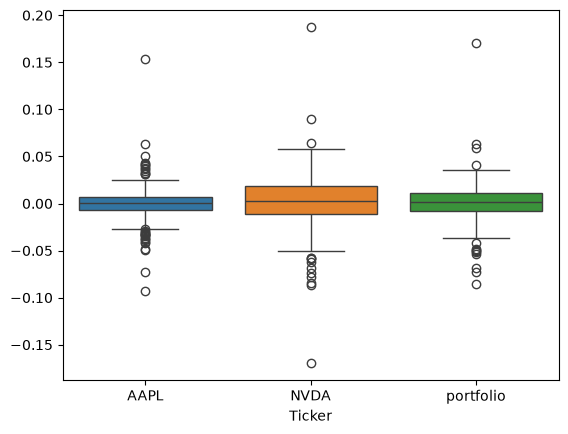

In [11]:
import yfinance as yf
import numpy as np
import seaborn as sns

# closing prices AAPL, NVDA y QQQ
returns = (yf.download(['AAPL', 'QQQ', 'NVDA'], start = "2025-01-01", end = "2025-12-31")['Close']).pct_change().dropna()

# daily portfolio returns

weights = np.array([0.5, 0.5])
returns['portfolio'] = returns[['AAPL', 'NVDA']].values @ weights
print(returns)
# summary statistics
print(returns.describe())

# plotting boxplot
print(sns.boxplot(data = returns[['AAPL', 'NVDA', 'portfolio']]))

### 2. Time Value of Money & Markov Chains *(Sessions 1 & 2)*
* **Compound Interest:** Assuming an initial investment of **USD 10,000** compounds at the portfolio's average daily return ($\bar{r}$) over $252$ trading days, calculate the projected ending capital using $C_n = C_0 (1 + \bar{r})^{252}$.
* **Markov Chains:** Assume a 2-state market regime (**Bull** and **Bear**) governed by the following transition matrix:
  $$P = \begin{pmatrix} 0.80 & 0.20 \\ 0.35 & 0.65 \end{pmatrix}$$
  Given an initial state vector $v_0 = [1, 0]$ ($100\%$ Bull today), compute the state probability distribution after **3 trading days** ($v_3 = v_0 \cdot P^3$).

In [19]:
c0 = 10000
c_mean = returns['portfolio'].mean()
days = 252

cn = c0 * (1 + c_mean) ** days
print(f"Compound Interest after 252 days is {cn}")

p = np.array([[0.8, 0.2], [0.35, 0.65]])
w = np.array([1, 0])
w_prima = w @ np.linalg.matrix_power(p, 3)
print(w_prima)

Compound Interest after 252 days is 13531.952558011464
[0.6695 0.3305]
